# 30 · Transformers, the big picture: what happens between your text and the next word

Every model in this course, from the 135-million-parameter one below to the 7B models served by Ollama and the frontier models behind APIs, does the same thing: **read a sequence of tokens and output a probability for every possible next token**. Then pick one, append it, and repeat.

Before building any of the pieces (the rest of the course), this notebook opens a small real model, **SmolLM2-135M** (Hugging Face, Llama architecture, trained on 2 trillion tokens), and follows one sentence through it:

| step | question | what you will see |
|---|---|---|
| 1. text → tokens | what does the model actually read? | the pieces, their ids, why Spanish costs more tokens than English |
| 2. tokens → vectors | how does a token become numbers? | the embedding table, and which tokens end up close to each other |
| 3. attention | how do tokens use each other? | attention maps: what "it" looks at |
| 4. the layers | where is the answer computed? | the prediction read out after every layer ("logit lens") |
| 5. next token | what comes out? | the probability distribution, temperature, and generation one token at a time |
| 6. size | where do the parameters live? | embeddings vs attention vs feed-forward, here and in a 7B model |

No training and no math beyond a dot product. Everything is measured on the real model, on CPU or GPU, in a couple of minutes.

**Read this first**, then notebook 00 (a complete mini LLM built from scratch), then the architecture notebooks that take each piece apart.

**Sources.** Vaswani et al. (2017), *Attention Is All You Need*; Alammar and Grootendorst, *Hands-On Large Language Models*, ch. 1–3; Raschka, *Build a Large Language Model (From Scratch)*, ch. 1–3; Stanford CME 295, lectures 1–2; nostalgebraist (2020), *interpreting GPT: the logit lens*; Allal et al. (2025), *SmolLM2*.

## Background: the whole pipeline in one picture

```
"The capital of France is"
        │  tokenizer (notebook 01)
        ▼
[ 5 integers ]                              token ids (section 1 prints them)
        │  embedding table: one learned vector per id
        ▼
5 vectors of 576 numbers
        │  × 30 transformer blocks, each:
        │     attention   (every token gathers information from the tokens before it;  notebooks 02-03)
        │     feed-forward (each token's vector is transformed on its own;            notebook 04)
        ▼
5 vectors of 576 numbers, now "contextual"
        │  output head: dot product of the LAST vector with every token's vector
        ▼
49,152 scores (logits) → softmax → probabilities → " Paris"
```

Three ideas carry everything:
- **Tokens are just ids.** The model never sees letters; it sees indices into a vocabulary.
- **Meaning is a direction in space.** Each id becomes a vector; training arranges vectors so that useful relations are geometric.
- **Attention is a learned lookup.** Each token builds a *query*, compares it with every earlier token's *key*, and takes a weighted average of their *values*. Causal masking means a token can only look backwards, which is what lets the model generate left to right.

Training (notebooks 05, 07–08) only ever adjusts the numbers so that the probability of the true next token goes up, over trillions of examples.

In [1]:
import os, sys, json, time, random
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, ROOT)                     # so `llm_edu_suite` imports from any notebooks/ sub-folder
import numpy as np
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)

import warnings; warnings.filterwarnings("ignore")
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
transformers.logging.set_verbosity_error()
from huggingface_hub.utils import logging as hf_logging, disable_progress_bars; hf_logging.set_verbosity_error(); disable_progress_bars()
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
NAME = "HuggingFaceTB/SmolLM2-135M"
tok = AutoTokenizer.from_pretrained(NAME)
model = AutoModelForCausalLM.from_pretrained(NAME, attn_implementation="eager", torch_dtype=torch.float32).to(device).eval()
cfg = model.config
print(f"{NAME}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters | vocabulary {cfg.vocab_size:,} | "
      f"{cfg.num_hidden_layers} layers | hidden size {cfg.hidden_size} | {cfg.num_attention_heads} attention heads "
      f"({cfg.num_key_value_heads} key/value heads) | context {cfg.max_position_embeddings:,} tokens | device {device}")

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  47%|████▋     | 129/272 [00:00<00:00, 1269.91it/s]

Loading weights:  94%|█████████▍| 256/272 [00:00<00:00, 1165.65it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1193.38it/s]

HuggingFaceTB/SmolLM2-135M: 134.5M parameters | vocabulary 49,152 | 30 layers | hidden size 576 | 9 attention heads (3 key/value heads) | context 8,192 tokens | device cuda


## 1. Text → tokens

In [2]:
text = "The capital of France is"
ids = tok(text)["input_ids"]
print("ids:   ", ids)
print("pieces:", [tok.decode([i]) for i in ids])

pairs = [("The weather is nice today and I want to go for a walk.", "Hoy hace buen tiempo y quiero salir a dar un paseo."),
         ("Tokenization splits text into pieces from a fixed vocabulary.", "La tokenización divide el texto en piezas de un vocabulario fijo."),
         ("The model predicts the next token.", "El modelo predice el siguiente token.")]
ratios = []
print()
for en, es in pairs:
    n_en, n_es = len(tok(en)["input_ids"]), len(tok(es)["input_ids"])
    ratios.append(n_es / n_en)
    print(f"EN {n_en:2d} tokens | ES {n_es:2d} tokens | {[tok.decode([i]) for i in tok(es)['input_ids']]}")
print(f"\nSpanish needs {np.mean(ratios):.2f}x the tokens of English for the same content with this tokenizer")
for w in ("123456789", "  indentation", "ChatGPT", "electroencefalografista"):
    print(f"{w!r:28s} -> {[tok.decode([i]) for i in tok(w)['input_ids']]}")

ids:    [504, 3575, 282, 4649, 314]
pieces: ['The', ' capital', ' of', ' France', ' is']

EN 14 tokens | ES 22 tokens | ['H', 'oy', ' ha', 'ce', ' bu', 'en', ' ti', 'em', 'po', ' y', ' qu', 'ier', 'o', ' sal', 'ir', ' a', ' dar', ' un', ' p', 'ase', 'o', '.']
EN 11 tokens | ES 21 tokens | ['La', ' token', 'iz', 'ación', ' divide', ' el', ' text', 'o', ' en', ' pie', 'z', 'as', ' de', ' un', ' vocab', 'ular', 'io', ' f', 'ij', 'o', '.']
EN  7 tokens | ES 12 tokens | ['El', ' model', 'o', ' pred', 'ice', ' el', ' sig', 'u', 'ient', 'e', ' token', '.']

Spanish needs 1.73x the tokens of English for the same content with this tokenizer
'123456789'                  -> ['1', '2', '3', '4', '5', '6', '7', '8', '9']
'  indentation'              -> [' ', ' indent', 'ation']
'ChatGPT'                    -> ['Chat', 'GPT']
'electroencefalografista'    -> ['elect', 'ro', 'ence', 'f', 'alog', 'raf', 'ista']


**What the tokenizer shows.**
- **The model reads integers.** "The capital of France is" becomes 5 tokens, `[504, 3575, 282, 4649, 314]`. Most English words are one token, and the leading space is part of the token (`' capital'`).
- **Spanish costs 1.73x more tokens** than English for the same sentences ("tiempo" → `ti`, `em`, `po`). SmolLM2 was trained mostly on English, so its vocabulary has few Spanish pieces. That makes Spanish text:
  - slower to generate;
  - more expensive per API call;
  - quicker to fill the context window.

  Multilingual tokenizers (Qwen, Llama 3, GPT-4o) close much of that gap.
- **Edge cases.**
  - Digits are split one by one: `123456789` is 9 tokens. That is one reason small models struggle with arithmetic.
  - Spaces get their own tokens.
  - Rare words fall apart into fragments (`electroencefalografista` is 7 pieces).

Notebook 01 builds a BPE tokenizer from scratch.

## 2. Tokens → vectors

The first layer of the model is a table with one row per token id: 49,152 rows of 576 numbers. Looking up a row *is* the embedding. After training, tokens used in similar contexts get similar rows. We measure that with the cosine similarity between rows.

In [3]:
E = model.get_input_embeddings().weight.detach().float()
En = torch.nn.functional.normalize(E, dim=-1)
print("embedding table:", tuple(E.shape))
def neighbours(word, k=8):
    i = tok(word, add_special_tokens=False)["input_ids"]
    if len(i) != 1: return f"{word!r} is {len(i)} tokens"
    sims = En @ En[i[0]]
    top = sims.topk(k + 1).indices.tolist()[1:]
    return ", ".join(f"{tok.decode([j]).strip()!r} {sims[j]:.2f}" for j in top)
for w in (" Paris", " Monday", " dog", " seven", " happy", " Python"):
    print(f"{w.strip():8s} -> {neighbours(w)}")
rnd = torch.randint(0, E.shape[0], (2000,), device=E.device)
print(f"\ncosine between random token pairs: mean {(En[rnd[:1000]] * En[rnd[1000:]]).sum(-1).mean():.3f}")

embedding table: (49152, 576)


Paris    -> 'Paris' 0.83, 'London' 0.60, 'Berlin' 0.59, 'Montreal' 0.58, 'France' 0.58, 'Barcelona' 0.58, 'Madrid' 0.58, 'Brussels' 0.58
Monday   -> 'Tuesday' 0.92, 'Wednesday' 0.90, 'Thursday' 0.90, 'Saturday' 0.85, 'Friday' 0.84, 'Sunday' 0.82, 'Sundays' 0.69, 'Monday' 0.68
dog      -> 'Dog' 0.82, 'dogs' 0.76, 'Dog' 0.75, 'dog' 0.72, 'Dogs' 0.62, 'Dogs' 0.62, 'dogs' 0.59, 'cat' 0.59
seven    -> 'eight' 0.89, 'six' 0.89, 'nine' 0.88, 'five' 0.84, 'four' 0.79, 'twelve' 0.75, 'eleven' 0.74, 'seven' 0.72
happy    -> 'happy' 0.74, 'Happy' 0.69, 'unhappy' 0.65, 'happier' 0.63, 'happiness' 0.63, 'Happy' 0.61, 'happily' 0.61, 'satisfied' 0.55
Python   -> 'python' 0.84, 'Python' 0.80, 'python' 0.72, 'Perl' 0.63, 'PHP' 0.63, 'Java' 0.62, 'Java' 0.61, 'NumPy' 0.59

cosine between random token pairs: mean 0.445


**What the embedding table shows.**
- **Neighbours make sense** without anyone having taught the model a single definition:
  - Paris → London, Berlin, Madrid;
  - Monday → Tuesday, Wednesday (0.92, 0.90);
  - seven → eight, six, nine;
  - Python → Perl, PHP, Java, NumPy.

  Training to predict the next token is enough to put tokens used in similar contexts close together.
- **Repeated neighbours** ('Dog', 'Dog', 'dogs', 'Dogs') are *different tokens*: with and without a leading space, upper and lower case. The model has to learn each variant separately.
- **The baseline matters.** Two random tokens already have a cosine of 0.445 on average, because the vectors share a common direction. A similarity of 0.59 to 'cat' is meaningful only relative to that baseline, which is why notebook 21 (embeddings) always compares against one.

These are input embeddings, one fixed vector per token. The vectors *after* the layers depend on the context, and those are the ones used for search and RAG (notebooks 21 and 10).

## 3. Attention: how tokens use each other

In every layer, each of the 9 heads gives each token a probability distribution over the tokens before it (the attention weights). The sentence below is the classic test: to predict well after "it", the model must know what "it" refers to. We look at the weights from "it" to the earlier tokens, per layer, averaged over heads, and at the most "animal-focused" head.

12 tokens: ['The', ' animal', ' didn', "'t", ' cross', ' the', ' street', ' because', ' it', ' was', ' too', ' tired']
attention from 'it' to 'animal', averaged over heads, per layer: [0.05, 0.01, 0.01, 0.07, 0.08, 0.05, 0.01, 0.01, 0.02, 0.08, 0.01, 0.02, 0.03, 0.09, 0.04, 0.09, 0.08, 0.02, 0.02, 0.03, 0.01, 0.06, 0.07, 0.02, 0.0, 0.06, 0.01, 0.03, 0.04, 0.02]
most 'animal'-focused head: layer 13, head 8: 0.73 on 'animal' vs 0.02 on 'street'
share of attention every token puts on the FIRST token, averaged over all layers and heads: 0.61


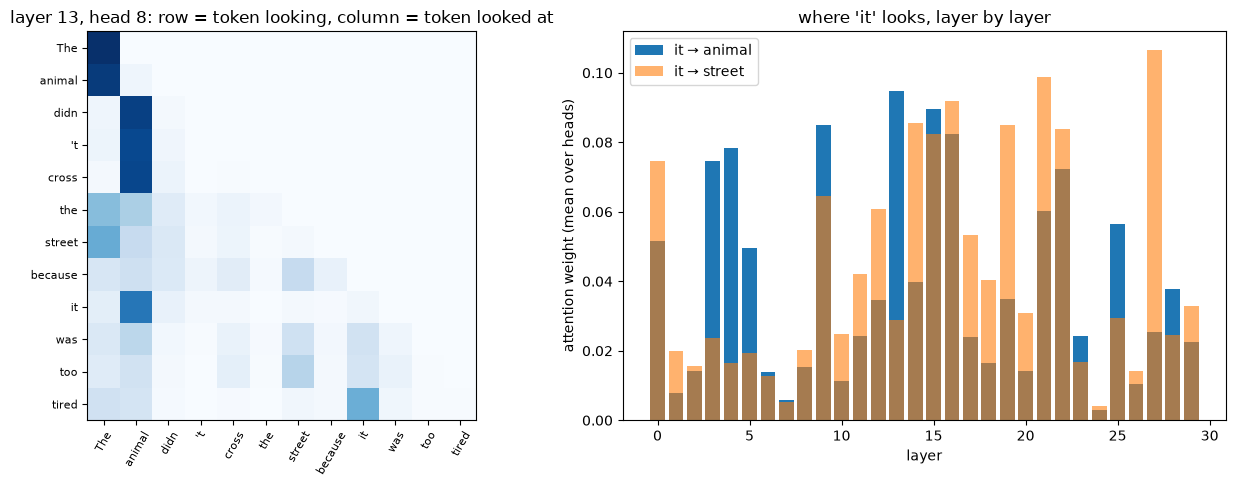

In [4]:
sent = "The animal didn't cross the street because it was too tired"
enc = tok(sent, return_tensors="pt").to(device)
pieces = [tok.decode([i]) for i in enc["input_ids"][0]]
with torch.no_grad():
    out = model(**enc, output_attentions=True, output_hidden_states=True)
A = torch.stack(out.attentions)[:, 0].float().cpu()            # layers x heads x query x key
it = pieces.index(" it"); animal = pieces.index(" animal"); street = pieces.index(" street")
to_animal, to_street = A[:, :, it, animal], A[:, :, it, street]
L, H = to_animal.shape
best = divmod(int(to_animal.argmax()), H)
print(f"{len(pieces)} tokens: {pieces}")
print(f"attention from 'it' to 'animal', averaged over heads, per layer: {[round(float(x), 2) for x in to_animal.mean(1)]}")
print(f"most 'animal'-focused head: layer {best[0]}, head {best[1]}: {to_animal[best]:.2f} on 'animal' vs {to_street[best]:.2f} on 'street'")
print(f"share of attention every token puts on the FIRST token, averaged over all layers and heads: {A[:, :, 1:, 0].mean():.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(A[best[0], best[1]], cmap="Blues"); ax[0].set_title(f"layer {best[0]}, head {best[1]}: row = token looking, column = token looked at")
ax[0].set_xticks(range(len(pieces))); ax[0].set_xticklabels(pieces, rotation=60, fontsize=8)
ax[0].set_yticks(range(len(pieces))); ax[0].set_yticklabels(pieces, fontsize=8)
ax[1].bar(range(L), to_animal.mean(1), label="it → animal"); ax[1].bar(range(L), to_street.mean(1), alpha=.6, label="it → street")
ax[1].set_xlabel("layer"); ax[1].set_ylabel("attention weight (mean over heads)"); ax[1].legend(); ax[1].set_title("where 'it' looks, layer by layer")
plt.tight_layout(); plt.show()

**What the attention maps show.**
- **Averaged over heads, "it" barely looks at "animal".** The weight stays between 0.00 and 0.09 in every layer, because most heads do other jobs.
- **One specialist head resolves the reference.** Layer 13, head 8 (counting from 0) puts **0.73 on "animal" and 0.02 on "street"**. Heads specialize, and averages hide them.
- **The attention sink.** On average, 61% of all attention goes to the *first token*, whatever it is. A softmax must put its weight somewhere, and the first token becomes a parking spot when a head has nothing useful to attend to. This is why:
  - streaming/long-context methods keep the first tokens in the KV cache (StreamingLLM);
  - some models add explicit sink tokens or gated attention.

Notebook 02 builds attention from scratch, with RoPE and normalization, and notebook 03 makes it efficient.

## 4. The layers: where is the answer computed?

After each block, the vector of the last token can be pushed through the model's final norm and output head as if it were the last layer. This **logit lens** shows what the model "would say" at that depth. We do it for a few factual prompts and record the layer where the right answer first becomes the top prediction.

'The capital of France is'     answer ' Paris'   top-10 from layer 30 | top-1 from layer None of 30 | final p = 0.09 | rank at layers 10/20/25/30: [2914, 3118, 233, 2] | top token at layer 20: ' '
'The capital of Japan is'      answer ' Tokyo'   top-10 from layer 30 | top-1 from layer 30 of 30 | final p = 0.18 | rank at layers 10/20/25/30: [15629, 20984, 865, 1] | top token at layer 20: ' '


'Monday, Tuesday, Wednesday,'  answer ' Thursday' top-10 from layer 25 | top-1 from layer 30 of 30 | final p = 0.80 | rank at layers 10/20/25/30: [11116, 4433, 8, 1] | top token at layer 20: ' and'
'The opposite of hot is'       answer ' cold'    top-10 from layer 26 | top-1 from layer 28 of 30 | final p = 0.85 | rank at layers 10/20/25/30: [1565, 1707, 37, 1] | top token at layer 20: ' '


'One, two, three, four,'       answer ' five'    top-10 from layer 27 | top-1 from layer 30 of 30 | final p = 0.29 | rank at layers 10/20/25/30: [837, 546, 19, 1] | top token at layer 20: ' '
'The Eiffel Tower is in'       answer ' Paris'   top-10 from layer 30 | top-1 from layer None of 30 | final p = 0.24 | rank at layers 10/20/25/30: [3232, 3732, 309, 2] | top token at layer 20: ' '


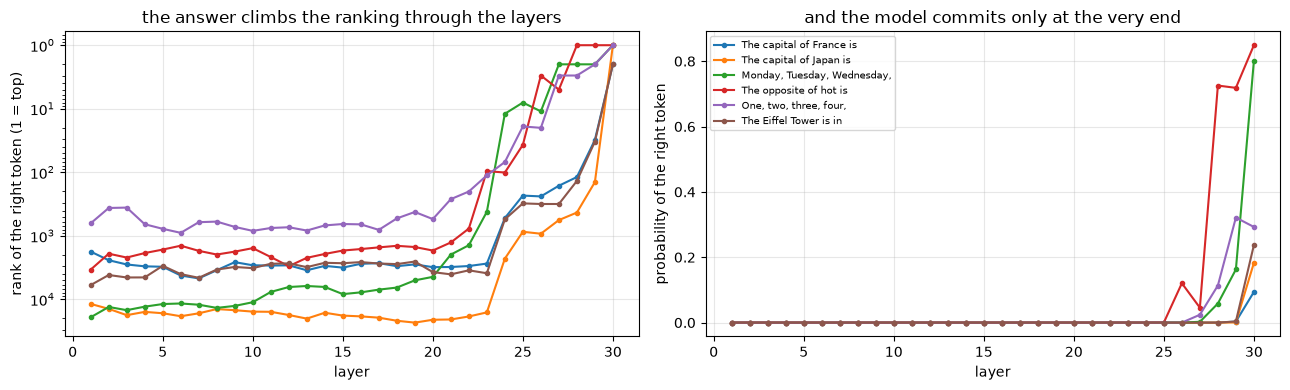

In [5]:
def logit_lens(prompt, answer):
    enc = tok(prompt, return_tensors="pt").to(device)
    target = tok(answer, add_special_tokens=False)["input_ids"][0]
    with torch.no_grad():
        hs = model(**enc, output_hidden_states=True).hidden_states       # embeddings + one per layer
        rows = []
        for i, h in enumerate(hs[1:], 1):
            x = h[0, -1] if i == len(hs) - 1 else model.model.norm(h[0, -1])   # transformers returns the last one already normed
            p = model.lm_head(x).float().softmax(-1)
            rank = int((p > p[target]).sum()) + 1                               # 1 = top prediction
            rows.append((tok.decode([int(p.argmax())]), float(p[target]), rank))
    first = next((i + 1 for i, r in enumerate(rows) if r[2] == 1), None)       # first layer (1-based) where it is top-1
    return rows, first
PROMPTS = [("The capital of France is", " Paris"), ("The capital of Japan is", " Tokyo"), ("Monday, Tuesday, Wednesday,", " Thursday"),
           ("The opposite of hot is", " cold"), ("One, two, three, four,", " five"), ("The Eiffel Tower is in", " Paris")]
LENS = {}
for p, a in PROMPTS:
    rows, first = logit_lens(p, a); LENS[p] = (rows, first)
    top10 = next((i + 1 for i, r in enumerate(rows) if r[2] <= 10), None)
    print(f"{p!r:30s} answer {a!r:10s} top-10 from layer {top10} | top-1 from layer {first} of {L} | final p = {rows[-1][1]:.2f} | "
          f"rank at layers 10/20/25/30: {[rows[i][2] for i in (9, 19, 24, 29)]} | top token at layer 20: {rows[19][0]!r}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p, (rows, _) in LENS.items():
    ax[0].plot(range(1, L + 1), [r[2] for r in rows], marker=".", label=p)
    ax[1].plot(range(1, L + 1), [r[1] for r in rows], marker=".", label=p)
ax[0].set_yscale("log"); ax[0].invert_yaxis(); ax[0].set_xlabel("layer"); ax[0].set_ylabel("rank of the right token (1 = top)"); ax[0].grid(alpha=.3)
ax[0].set_title("the answer climbs the ranking through the layers")
ax[1].set_xlabel("layer"); ax[1].set_ylabel("probability of the right token"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
ax[1].set_title("and the model commits only at the very end"); plt.tight_layout(); plt.show()

**What the logit lens shows.**
- **The answer is computed late.** At layers 10 and 20, the right token sits at rank ~550 to ~21,000 out of 49,152 and the top prediction is mostly a space or ' and'. By layer 25 it has climbed into the top 10 for the easy patterns (Thursday 8th, five 19th, cold 37th). It becomes top-1 only at layers 28–30.
- **The last few layers commit.** The probability of the right token stays near 0 for 25 layers and jumps at the end:
  - Thursday 0.80;
  - cold 0.85;
  - five 0.29;
  - Tokyo 0.18.
- **The model knows Paris but prefers ' the'.** For "The capital of France is" and "The Eiffel Tower is in", Paris ends at **rank 2** (p 0.09 and 0.24). ' the' wins ("...is the capital of..."), a perfectly grammatical continuation. *Knowing* the fact and *saying* it next are different things.
- **A caveat:** the lens reads intermediate layers with the final norm and head, which were trained only on the last layer. In small models the middle layers are not "wrong", they are in a different basis. The *tuned lens* trains one small adapter per layer for a fairer reading.

Interpretability tools of this kind are how researchers locate facts inside models (and edit them, as in ROME).

## 5. The next token: a distribution, then a choice

In [6]:
enc = tok("The capital of France is", return_tensors="pt").to(device)
with torch.no_grad():
    logits = model(**enc).logits[0, -1].float()
for T in (0.5, 1.0, 1.5):
    p = (logits / T).softmax(-1); top = p.topk(6)
    ent = -(p * p.clamp_min(1e-12).log()).sum()
    print(f"temperature {T}: " + ", ".join(f"{tok.decode([int(i)])!r} {float(v):.2f}" for v, i in zip(top.values, top.indices))
          + f" | entropy {ent:.2f} nats")

# Generation is just this, in a loop: predict, pick, append. Here greedy, with the KV cache doing the bookkeeping.
ids = enc["input_ids"]; past = None; steps = []
with torch.no_grad():
    for _ in range(12):
        o = model(input_ids=ids[:, -1:] if past is not None else ids, past_key_values=past, use_cache=True)
        past = o.past_key_values
        nxt = o.logits[0, -1].argmax().view(1, 1); ids = torch.cat([ids, nxt], 1)
        steps.append(tok.decode(nxt[0]))
print("\ngreedy, token by token:", steps)
print("text:", tok.decode(ids[0]))

temperature 0.5: ' the' 0.77, ' Paris' 0.10, ' located' 0.06, ' called' 0.02, ' a' 0.02, ' situated' 0.01 | entropy 0.93 nats
temperature 1.0: ' the' 0.26, ' Paris' 0.09, ' located' 0.07, ' called' 0.04, ' a' 0.04, ' situated' 0.04 | entropy 4.41 nats
temperature 1.5: ' the' 0.05, ' Paris' 0.03, ' located' 0.02, ' called' 0.02, ' a' 0.01, ' situated' 0.01 | entropy 7.80 nats



greedy, token by token: [' the', ' capital', ' of', ' the', ' country', '.', '\n', '\n', 'The', ' capital', ' of', ' France']
text: The capital of France is the capital of the country.

The capital of France


**What the output distribution shows.**
- **The output is a distribution, not an answer.**
  - At temperature 1.0: ' the' 26%, ' Paris' 9%, ' located' 7%, and a long tail. The entropy is 4.41 nats, so thousands of tokens share the rest.
  - **Temperature 0.5** sharpens it (' the' 77%, entropy 0.93).
  - **Temperature 1.5** flattens it (entropy 7.80), and sampling then often picks nonsense from the tail.

  Every "creativity" setting of an API is this division of the logits.
- **Greedy decoding is not "the best answer".** Always taking the top token produced *"The capital of France is the capital of the country. The capital of France"*: bland, circular, and it starts repeating itself. That is why real systems:
  - sample with temperature, top-p or min-p;
  - add repetition penalties;
  - instruction-tune the model so the most likely continuation is a direct answer (notebooks 07 and 08).
- **The KV cache** made each new step read only the newest token: the keys and values of the earlier ones were kept. That cache is what notebook 06 (serving) and notebook 03 (efficient attention) optimize.

## 6. Where the parameters live

In [7]:
groups = {"embeddings (shared with the output head)": 0, "attention (q, k, v, o)": 0, "feed-forward (gate, up, down)": 0, "norms": 0}
for n, p in model.named_parameters():
    if "embed" in n: groups["embeddings (shared with the output head)"] += p.numel()
    elif "self_attn" in n: groups["attention (q, k, v, o)"] += p.numel()
    elif "mlp" in n: groups["feed-forward (gate, up, down)"] += p.numel()
    else: groups["norms"] += p.numel()
total = sum(groups.values())
for k, v in groups.items():
    print(f"{k:42s} {v / 1e6:7.1f}M  {v / total:6.1%}")
# The same formula for Qwen2.5-7B's published configuration
d, ff, layers, vocab, heads, kv = 3584, 18944, 28, 152064, 28, 4
att = layers * (d * d + 2 * d * (d // heads * kv) + d * d); mlp = layers * 3 * d * ff; emb = 2 * vocab * d
print(f"\nQwen2.5-7B (from its config): embeddings + head {emb / 1e9:.2f}B ({emb / (att + mlp + emb):.0%}) | attention {att / 1e9:.2f}B "
      f"({att / (att + mlp + emb):.0%}) | feed-forward {mlp / 1e9:.2f}B ({mlp / (att + mlp + emb):.0%})")

embeddings (shared with the output head)      28.3M   21.0%
attention (q, k, v, o)                        26.5M   19.7%
feed-forward (gate, up, down)                 79.6M   59.2%
norms                                          0.0M    0.0%

Qwen2.5-7B (from its config): embeddings + head 1.09B (14%) | attention 0.82B (11%) | feed-forward 5.70B (75%)


**Where the parameters live.**
- **SmolLM2-135M:**
  - feed-forward layers: 59.2%;
  - attention: 19.7%;
  - embedding table, shared with the output head: 21.0%;
  - norms: almost nothing.
- **Qwen2.5-7B, by the same formula from its published config:**
  - feed-forward: 75%;
  - attention: only 11%, thanks to grouped-query attention (4 key/value heads for 28 query heads);
  - embeddings plus head: 14%.

  That adds up to the ~7.6B the model card reports.
- **Most of a model's "knowledge" is in its feed-forward layers**, which is why:
  - mixture-of-experts architectures (notebook 04) split exactly those layers;
  - LoRA (notebook 07) often targets them alongside attention.
- **The vocabulary is expensive for small models.** A 49k vocabulary eats a fifth of a 135M model. A 152k vocabulary is only 14% of a 7B one.

## Results

| step | measured on SmolLM2-135M | lesson |
|---|---|---|
| tokens | "The capital of France is" = 5 tokens; Spanish 1.73x English; digits one per token | cost, speed and context are counted in tokens, and they are not equal across languages |
| embeddings | Monday → Tuesday 0.92; seven → eight 0.89; random pairs 0.445 | meaning emerges from next-token prediction; compare to a baseline |
| attention | one head (13, 8): 0.73 on "animal" vs 0.02 on "street"; 61% of attention on the first token | heads specialize; the attention sink is real |
| layers (logit lens) | the right token at rank ~550–21,000 by layer 20, top-10 by layer 25–30, top-1 at 28–30 | the answer is assembled through depth and committed at the end |
| next token | ' the' 26% vs ' Paris' 9% at T = 1; entropy 0.93 / 4.41 / 7.80 nats at T = 0.5 / 1 / 1.5 | generation = a distribution plus a decoding rule |
| parameters | 59% feed-forward here; 75% in Qwen2.5-7B, attention 11% thanks to GQA | the feed-forward layers are most of the model |

## In production

**Count tokens, not words.**
- Prices, rate limits, latency and context windows are all in tokens.
- Measure your real traffic with the deployed model's tokenizer. Non-English text, code and numbers can cost 1.5–3x more.
- Choose a model with a tokenizer suited to your languages.

**Decoding settings are product settings.**
- Use temperature 0 or low for extraction, classification and tool calls.
- Use moderate temperature with top-p or min-p for writing.
- Never use greedy decoding on a base model for open-ended text.
- Log the settings with every request, so results can be reproduced (as far as GPUs allow, see notebook 27).

**Memory is parameters plus KV cache.**
- Weights: parameters × bytes per parameter. A 7B model is ~15 GB at bf16 and ~4.5 GB at 4 bits (notebook 09).
- KV cache: it grows with context length × layers × key/value heads. This is why GQA and the cache optimizations of notebooks 03 and 06 matter.

**Interpretability.**
- Logit lens, attention maps and probes are debugging tools, not explanations.
- Use them to locate where a behaviour appears, then confirm with an intervention: ablate the head or patch the activation.

**Failure modes.**
- Assuming one word is one token.
- Reading a single attention head (or an average of all of them) as "what the model thinks".
- Treating the top-1 token as the model's knowledge.
- Forgetting that the tokenizer and the model must match exactly.

**Next:** notebook 00 (build a complete mini LLM from scratch), then notebooks 01–04 to take each piece apart.